---
tags: [algorithm, chemistry, variational]
---

# 厳密な分子シミュレーションのための適応的・変分的アルゴリズム

化学系の量子シミュレーションは、近い将来の量子コンピュータの応用分野として注目されています。
量子ハードウェア上で分子シミュレーションを行う手法としては、変分量子固有値ソルバー (VQE) が有名です。
しかしこの手法で得られる結果は、事前に選択された波動関数アンザッツに大きく依存するという制限があります。
そこで [Grimsley et al. (2019)](https://www.nature.com/articles/s41467-019-10988-2) では、アンザッツを事前に固定するのでなく、計算対象の分子に応じて演算子を 1 つずつ追加していくことで構築する 手法を提案しました。
この手法により、パラメータ数が少なく、回路 depth が浅いアンザッツの生成が可能になります。
ここでは Qamomile を用い、提案手法である ADAPT-VQE を実装してみましょう。

In [1]:
from itertools import combinations, product

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from qiskit_aer.primitives import EstimatorV2

from openfermion import (
    FermionOperator,
    commutator,
    hermitian_conjugated,
    jordan_wigner,
    normal_ordered,
)
from openfermion.chem import MolecularData
from openfermion.transforms import get_fermion_operator
from openfermionpyscf import run_pyscf

import qamomile.circuit as qmc
import qamomile.observable as qmo
from qamomile.qiskit import QiskitTranspiler
from qamomile.qiskit.transpiler import QiskitExecutor

## 背景

### 量子化学計算と VQE

分子状態の計算において、分子に付随する電子状態を表す空間は、その軌道数の増加とともに指数的に増大します。
このために、古典計算機を用いた量子化学計算には限界があり、そして量子計算はこの限界を突破できると期待されています。
しかし、それを実現するには量子コンピュータ性能や量子ビット数・量子ビット品質だけでなく、効率的な量子アルゴリズムが重要となります。
そのための手法として、VQE が注目を集めています。
これは状態準備・測定を量子コンピュータ上で行い、パラメータの更新を古典側で行うというものです。
測定回数が増える欠点がありますが、浅い回路での実行が可能であるため、NISQ デバイス実行に適しています。
しかし、VQE の精度はアンザッツの表現能力に依存します。
これを改善するためにハードウェア効率の良いアンザッツ (hardware-efficient ansatz) などが考えられてきましたが、強相関系を高精度で計算することは依然として困難でした。
そこで、[Grimsley et al. (2019)](https://www.nature.com/articles/s41467-019-10988-2) では、アンザッツを事前に固定せず、計算する分子に応じて構築する ADAPT-VQE を提案しました。

### 先行研究: 適応的な結合クラスター法 (@CC)

ADAPT-VQE の説明に入る前に、重要な先行研究である [Lyakh & Bartlett (2010)](https://pubs.aip.org/aip/jcp/article-abstract/133/24/244112/983180/An-adaptive-coupled-cluster-theory-CC-approach?redirectedFrom=fulltext) が提案した古典計算手法について触れておきましょう。
分子の電子状態を計算するために、初期条件としてハートリー・フォック法で得られた状態 $\vert \Phi_\mathrm{HF} \rangle$ を用います。
結合クラスター (CC) 法では、これに次のような演算子を作用させます。

$$
\vert \Psi_\mathrm{CC} \rangle 
= e^T \vert \Phi_\mathrm{HF} \rangle \tag{1}
$$

ここで

$$
T 
= T_1 + T_2 + \cdots 
= \sum_{i, a} t_{ia} a_a^\dagger a_i + \frac{1}{4} \sum_{i, j, a, b} t_{ij}^{ab} a_a^\dagger a_b^\dagger a_j a_i + \cdots \tag{2}
$$

は励起演算子であり、$T_1$ は単一電子励起、$T_2$ は二電子励起、などに対応します。
さらに $a_p^\dagger, a_p$ はそれぞれ軌道 $p$ に電子を生成・消滅させる演算子です。
結合クラスター法では、指数関数の形で励起演算子を考慮したものと見ることができます。
単一電子励起演算子のみを考慮する場合には CCS 法、二電子励起まで考慮する場合には CCSD 法、三電子励起まで考慮する場合には CCSDT 法、などと呼び方が変わります。
通常の CC 法では、計算精度を高めるために CCS -> CCSD -> CCSDT のように、独立に扱う励起の次数を増やします。
しかし、この方法では同じ次数の中でも重要でない項まで全て含めて計算することになり、大量の振幅を扱う必要が出てきます。
そこで @CC 法では、重要と思われる励起のみを追加することを行います。
採用する励起の集合を $S$ とすると

$$
T_S 
= \sum_{\mu \in S} t_\mu \tau_\mu, \quad
\vert \Psi_S \rangle 
= e^{T_S} \vert \Phi_\mathrm{HF} \rangle \tag{3}
$$

のようにして、計算対象を設定することができます。
例えば計算例として

$$
T_S 
= T_1 + T_2 + \sum_{\mu \in S_3} t_\mu \tau_\mu + \sum_{\nu \in S_4} t_\nu \tau_\nu \tag{4}
$$

のようなものが考えられます。  
このとき、どの振幅を採用するかを表す集合 $S$、そして採用した振幅の値 $t_\mu$ を調整する必要があります。
@CC 法では重要度関数を用い、対象となる電子状態の記述に必要なクラスター振幅を選択します。
これにより、全ての励起演算子を一律に取り込むのではなく、問題に応じて計算モデルを構築することを目指しました。

## 提案手法

### ADAPT-VQE 

それでは、ADAPT-VQE を詳しくみていきましょう。
@CC 法と同様、出発点はハートリー・フォック法で得られた $\vert \Phi_\mathrm{HF} \rangle$ です。
これを用いると、CCSD は $\vert \Psi_\mathrm{CCSD} \rangle = e^{T_1 + T_2} \vert \Phi_\mathrm{HF} \rangle$ のように表されるのでした。
この状態を量子回路で準備するために、ユニタリな CCSD (UCCSD) を考える必要があります。
そこで、ユニタリな変換として

$$
K 
= T_1 - T_1^\dagger + T_2 - T_2^\dagger 
= A_1 + A_2 \quad (A_1 \equiv T_1 - T_1^\dagger, A_2 \equiv T_2 - T_2^\dagger) \tag{5}
$$

を用い

$$
\lvert \Psi_\mathrm{UCCSD} \rangle
= e^K \vert \Phi_\mathrm{HF} \rangle \tag{6}
$$

のようにします。
実際このようにすると、$K^\dagger = - K$ となり、$(e^K)^\dagger e^K = e^{-K} e^K = I$ のように、$e^K$ はユニタリとなります。  
通常の単一電子・二電子励起では、ハートリー・フォック状態における占有軌道 $i, j$ と非占有軌道 $a, b$ を区別します。
しかし、ADAPT-VQE で導入する一般化演算子では、軌道の組合せをハートリー・フォック状態の占有・非占有で制限は行いません。
このようにすることで、基準状態 (ハートリー・フォック状態) に直接作用させてもゼロとなる演算子も、候補に含めることができます。
ここまでは CCSD について考えてきましたが、一般に ADAPT-VQE で用いる状態は $\vert \Psi_\mathrm{UCCSD} \rangle = e^{\sum_\mu \theta_\mu A_\mu} \vert \Phi_\mathrm{HF} \rangle$ のように書かれます。
ここで、$\theta_\mu$ は各演算子の重みを決めるパラメータです。
これを量子回路で表現するために、個々のユニタリ変換の積として構成しましょう。
すなわち

$$
\vert \Psi_\mathrm{ADAPT} \rangle 
= e^{\theta_L A_{\mu_L}} e^{\theta_{L-1} A_{\mu_{L-1}}} \cdots e^{\theta_2 A_{\mu_2}} e^{\theta_1 A_{\mu_1}} \vert \Phi_\mathrm{HF} \rangle \tag{7}
$$

のように、トロッター分解のようにしてアンザッツを構成します。
ただし通常のトロッター分解 $e^{A + B} = \lim_{r \rightarrow \infty} (e^{A/r} e^{B/r})^r$ とは異なり、同じ係数を用いないことに注意が必要です。

### 演算子プールの構築と選択

先ほど示したとおり、基本となるのは電子の単一励起・二重励起と、それらのエルミート共役 (すなわち脱励起) を組合せた演算子です。
単一励起の場合

$$
A_{pq} 
=  a_p^\dagger a_q - a_q^\dagger a_p \tag{8}
$$

のようになります。
そして二重励起については

$$
B_{pqrs} 
= a_p^\dagger a_q^\dagger a_r a_s, \qquad 
A_{pqrs} 
= B_{pqrs} - B_{pqrs}^\dagger \tag{9}
$$

のような形となります。  
ADAPT-VQE では、式 (8), (9) の演算子を用い、回路の構成に使える演算子の候補集合 $\mathcal{P} = \{A_1, A_2, \dots, A_\mu, \dots, A_M\}$ をあらかじめ用意します。
例として、この集合の中から最初に $A_3$、次に $A_8$、そして最後に $A_2$ が選ばれたとしましょう。
すると状態は $\vert \Psi (\boldsymbol{\theta}) \rangle = e^{\theta_3 A_2} e^{\theta_2 A_8} e^{\theta_1 A_3} \vert \Phi_\mathrm{HF} \rangle$ のように計算されます。
選ばれた演算子は演算子プールからは取り除かれず、後の反復で再び選ばれることもあります。
次に作用させる演算子を決定するために、$k$ 個の演算子を追加し、パラメータ最適化を行うことで得られた状態を $\vert \Psi^{(k)} \rangle$ のように書きましょう。
候補となる演算子 $A_\mu$ を追加した状態と、そのエネルギーはそれぞれ

$$
\vert \Psi (\alpha) \rangle 
= e^{\alpha A_\mu} \vert \Psi^{(k)} \rangle, \qquad 
E_\mu (\alpha) 
= \langle \Psi^{(k)} \vert e^{-\alpha A_\mu} H e^{\alpha A_\mu} \vert \Psi^{(k)} \rangle \tag{10}
$$

のようになります。
ここから、まだ何も演算子を作用させていない $\alpha = 0$ における勾配を計算しましょう。
すると

$$
g_\mu 
= \left. \frac{dE_\mu (\alpha)}{d\alpha} \right\vert_{\alpha = 0} 
= \left. \langle \Psi^{(k)} \vert (-A_\mu e^{-\alpha A_\mu} H e^{\alpha A_\mu} + e^{-\alpha A_\mu} H A_\mu e^{\alpha A_\mu}) \vert \Psi^{(k)} \rangle \right\vert_{\alpha = 0}
= \langle \Psi^{(k)} \vert (-A_\mu H + H A_\mu) \vert \Psi^{(k)} \rangle 
= \langle \Psi^{(k)} \vert [H, A_\mu] \vert \Psi^{(k)} \rangle \tag{11}
$$

このようにして計算された勾配 $g_\mu$ から、勾配の絶対値の一番大きな演算子 $A_{\mu^\ast}$ を選択します。
正の勾配を持つものでも、それに対応するパラメータ $\theta_{k+1}$ を負にすれば良いため、符号を考慮せずに絶対値のみで判断します。
ただし、この選択手法で判断しているのは、現在の状態 $\vert \Psi^{(k)} \rangle$ の近傍での改善のしやすさです。
演算子追加後に最適化を行なったとき、最も大きくエネルギーを下げる演算子であるかどうかを厳密に探索しているわけではありません。  
選ばれた演算子を追加し、アンザッツを $\vert \Psi^{(k+1)} (\boldsymbol{\theta}) \rangle = e^{\theta_{k+1} A_{\mu^\ast}} e^{\theta_{k} A_{\mu_k}} e^{\theta_{k-1} A_{\mu_{k-1}}} \cdots e^{\theta_{1} A_{\mu_{1}}} \vert \Phi_\mathrm{HF} \rangle$ とします。そして通常の VQE を実行し

$$
\min_{\theta_1, \theta_2, \dots, \theta_{k+1}} \langle \Psi^{(k+1)} (\boldsymbol{\theta}) \vert H \vert \Psi^{(k+1)} (\boldsymbol{\theta}) \rangle \tag{12}
$$

を求めます。
最適化するのは、これまで追加されてきた演算子に対する全てのパラメータ $\theta_{k+1}, \theta_k, \dots, \theta_1$ です。
また $k + 1$ ステップ目の VQE 計算を行う際、パラメータの初期値は $\boldsymbol{\theta}_\mathrm{initial} = (\boldsymbol{\theta}^\ast, 0)$ のように、$k$ ステップ目のパラメータ最適化結果 $\boldsymbol{\theta}^\ast$ を用います。
新たに $k+1$ ステップ目で追加された演算子 $A_{\mu^\ast}$ に対するパラメータ $\theta_{k+1}$ の初期値は、ゼロとします。
$e^{0 A_{\mu^\ast}} = I$ であるため、追加された直後の状態は $k$ ステップ目の最適化結果から得られた状態と同じです。
したがって、$\theta_{k+1}$ の初期値をゼロにすることで、新しいアンザッツに自然に前回の解を含めることができます。

## Qamomile による実装

それでは、実際に Qamomile を用いて ADAPT-VQE を実装してみましょう。

### 計算する分子の設定

ここでは $\mathrm{H}_2$ 分子について計算しましょう。
エネルギーを計算する原子間距離をオングストローム単位で記述します。

In [2]:
# 核間距離 R [Å]。上から順番に実行し、必要に応じてこの配列を変更する。
bond_lengths = np.array([0.25, 0.50, 0.75, 1.0, 1.25, 1.5, 1.75, 2.00])
basis = "sto-3g"

gradient_threshold = 1e-3  # 規格化された演算子プールに対する閾値
max_adapt_steps = 6         # 各距離で追加できる演算子の最大数
max_vqe_iterations = 120    # 演算子を追加するたびに行う BFGS の最大反復回数

assert bond_lengths.ndim == 1 and len(bond_lengths) >= 2
assert np.all(bond_lengths > 0)
assert np.all(np.diff(bond_lengths) > 0), "距離は昇順かつ重複なしにしてください"
print("計算する距離 [Å]:", bond_lengths.tolist())
print("計算点数:", len(bond_lengths))

計算する距離 [Å]: [0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
計算点数: 8


### 量子ビット数の計算

STO-3G 基底での $\mathrm{H}_2$ は、2 空間軌道・4 スピン軌道・2 電子からなります。
同じ基底を用いる限り、距離を変更しても量子ビット数・電子数は変わらないため、演算子プールの構築は一度だけですみます。
そこで先ほど設定した原子間距離のうち、最小距離で分子モデルを作成し、さらにそこから必要量子ビット数を調べましょう。

In [3]:
first_R = float(bond_lengths[0])
first_geometry = [["H", [0.0, 0.0, 0.0]], ["H", [0.0, 0.0, first_R]]]
first_molecule = MolecularData(first_geometry, basis, multiplicity=1, charge=0)
first_molecule = run_pyscf(first_molecule, run_scf=True, run_fci=True)

n_qubits = first_molecule.n_qubits
n_electrons = first_molecule.n_electrons
n_spatial = n_qubits // 2

assert n_qubits == 4 and n_electrons == 2
print(f"量子ビット数: {n_qubits}, 電子数: {n_electrons}, 空間軌道数: {n_spatial}")
print(f"R={first_R:.2f} Å: HF={first_molecule.hf_energy:.10f} Ha, "
      f"FCI={first_molecule.fci_energy:.10f} Ha")

量子ビット数: 4, 電子数: 2, 空間軌道数: 2
R=0.25 Å: HF=-0.3050005338 Ha, FCI=-0.3122699027 Ha


### 一般化された単一・二重励起の列挙

ハートリー・フォックの占有軌道から非占有軌道への励起だけでなく、一般化された空間軌道の組合せを候補にします。
そしてここでは $\mathrm{H}_2$ のために、単純化されたフェルミオン演算子のプールを作成しています。

In [4]:
raw_pool = []

# スピン相補化した一般化単一励起。
for p, q in combinations(range(n_spatial), 2):
    T = (
        FermionOperator(((2*q, 1), (2*p, 0)))
        + FermionOperator(((2*q+1, 1), (2*p+1, 0)))
    )
    raw_pool.append((f"単一励起({p}->{q})", T))

# 異なるスピンの二重励起と、そのスピン入替え項。
for p, q, r, s in product(range(n_spatial), repeat=4):
    T = (
        FermionOperator(((2*r, 1), (2*s+1, 1), (2*q+1, 0), (2*p, 0)))
        + FermionOperator(((2*r+1, 1), (2*s, 1), (2*q, 0), (2*p+1, 0)))
    )
    raw_pool.append((f"二重励起_ab({p},{q}->{r},{s})", T))

# 同じスピンの二重励起と、そのスピン入替え項。
for p, q in combinations(range(n_spatial), 2):
    for r, s in combinations(range(n_spatial), 2):
        T = (
            FermionOperator(((2*r, 1), (2*s, 1), (2*q, 0), (2*p, 0)))
            + FermionOperator(((2*r+1, 1), (2*s+1, 1), (2*q+1, 0), (2*p+1, 0)))
        )
        raw_pool.append((f"二重励起_same({p},{q}->{r},{s})", T))

print("列挙した候補数（重複除去前）:", len(raw_pool))

列挙した候補数（重複除去前）: 18


### 反エルミート化・規格化・重複除去の処理

先ほど作成した励起演算子 $T_\mu$ から、$A_\mu = T_\mu - T_\mu^\dagger$ を作成します。
そして、係数ノルムを 1 に規格化します。
ただし、$A_\mu$ と $- A_\mu$ は、同じパラメータの符号を反転させるだけで実現できるため、この重複を取り除きます。

In [5]:
pool = []
pool_labels = []
seen = set()

for label, T in raw_pool:
    A = normal_ordered(T - hermitian_conjugated(T))
    A.compress()
    norm = np.sqrt(sum(abs(c)**2 for c in A.terms.values()))
    if norm < 1e-12:
        continue

    A = A / norm
    first_coeff = sorted(A.terms.items())[0][1]
    if first_coeff.real < 0:
        A = -A

    key = tuple(
        (term, round(float(coeff.real), 10), round(float(coeff.imag), 10))
        for term, coeff in sorted(A.terms.items())
    )
    if key in seen:
        continue
    seen.add(key)
    pool.append(A)
    pool_labels.append(label)

print("重複除去後の演算子プールの大きさ:", len(pool))
for j, label in enumerate(pool_labels):
    print(f"{j:2d}: {label}")
assert len(pool) > 0

重複除去後の演算子プールの大きさ: 4
 0: 単一励起(0->1)
 1: 二重励起_ab(0,0->0,1)
 2: 二重励起_ab(0,0->1,1)
 3: 二重励起_ab(0,1->1,1)


### オブザーバブルに変換

指数の肩に乗せる生成子 $G_\mu = i A_\mu$ を、ジョルダン・ウィグナー変換します。
このようにして変換された生成子から、$e^{-i\theta G_\mu} \ (=e^{\theta A_\mu})$ を準備します。

In [6]:
# H2 の一般化励起から作る生成子 G_mu = i*A_mu を Jordan-Wigner 変換。
# このセル以降で使う generators は、距離 R に依存しない。
pauli_factories = {"X": qmo.X, "Y": qmo.Y, "Z": qmo.Z}
generators = []

for A in pool:
    op = jordan_wigner(1j * A)
    obs = qmo.Hamiltonian()
    for term, coeff in op.terms.items():
        if abs(coeff.imag) > 1e-8:
            raise ValueError(f"生成子に複素係数が残っています: {coeff}")
        value = float(coeff.real)
        if abs(value) < 1e-12:
            continue
        if len(term) == 0:
            obs.constant += value
        else:
            pauli_product = qmo.Hamiltonian()
            pauli_product.constant = 1.0
            for qubit_index, symbol in term:
                pauli_product *= pauli_factories[symbol](qubit_index)
            obs += value * pauli_product
    generators.append(obs)

M = len(pool)
assert len(generators) == M and M > 0
print(f"演算子プールのサイズ: {M}")

演算子プールのサイズ: 4


### Qamomile の量子カーネルの作成

ハートリー・フォック状態 $\vert \Phi_\mathrm{HF} \rangle$ を作成し、選択された $G_\mu$ を順に適用、指定されたオブザーバブルの期待値を返すような量子カーネルを作成しましょう。
`observable` に $H$ を与えることで、エネルギーが計算できます。
さらに $[H, A_\mu]$ を与えることで、演算子選定に用いる勾配を計算することができます。

In [7]:
@qmc.qkernel
def adapt_vqe_kernel(
    n: qmc.UInt,
    n_electrons: qmc.UInt,
    n_layers: qmc.UInt,
    operators: qmc.Vector[qmc.Observable],
    thetas: qmc.Vector[qmc.Float],
    observable: qmc.Observable,
) -> qmc.Float:
    q = qmc.qubit_array(n, name="q")
    for i in qmc.range(n_electrons):
        q[i] = qmc.x(q[i])  # Hartree–Fock 状態の占有
    for i in qmc.range(n_layers):
        q = qmc.pauli_evolve(q, operators[i], thetas[i])
    return qmc.expval(q, observable)

### 距離ごとに ADAPT-VQE を実行する

いよいよ、各距離で ADAPT-VQE を実行していきましょう。
各距離 `R` ごとに、$\mathrm{H}_2$ のハミルトニアンを生成し、ハートリーフォック状態を計算します。
後の比較のために、FCI によるエネルギー計算も行います。
次に、演算子プール $\{A_\mu\}$ は共通のまま、$[H(R), A_\mu]$ を距離に応じて作ります。
各ステップで $g_\mu = \langle [H(R), A_\mu]\rangle$ を求め、$\vert g_\mu \vert$ が最大となる演算子を追加します。
そして追加のたびに、全ての変分パラメータを BFGS で最適化し、各距離の最終的なエネルギー・勾配ノルム・演算子数・選ばれた演算子を保存します。

:::{note} 本実装では Qamomile のパウリ時間発展を、基本ゲートへ展開しています。$\mathrm{LiH}$ や $\mathrm{H}_4$ 原子のように非可換なパウリ項を含む生成子が存在する場合、分解による近似誤差が生じる可能性があるため、注意が必要です。:::

In [13]:
transpiler = QiskitTranspiler(use_native_pauli_evolution=False)
executor = QiskitExecutor(estimator=EstimatorV2())

scan_results = []
selected_labels_by_distance = []
energy_traces_by_distance = []

for distance_index, distance in enumerate(bond_lengths):
    R = float(distance)
    print(f"\n[{distance_index+1}/{len(bond_lengths)}] R = {R:.3f} Å")

    # --- 1. この距離の分子ハミルトニアン、HF / FCI を取得する ---
    if distance_index == 0:
        molecule = first_molecule
    else:
        geometry = [["H", [0.0, 0.0, 0.0]], ["H", [0.0, 0.0, R]]]
        molecule = MolecularData(geometry, basis, multiplicity=1, charge=0)
        molecule = run_pyscf(molecule, run_scf=True, run_fci=True)

    assert molecule.n_qubits == n_qubits and molecule.n_electrons == n_electrons
    hf_energy = float(molecule.hf_energy)
    fci_energy = float(molecule.fci_energy)
    fermionic_H = get_fermion_operator(molecule.get_molecular_hamiltonian())
    qubit_H_of = jordan_wigner(fermionic_H)

    # --- 2. H(R) と全ての [H(R), A_mu] を Qamomile Observable へ変換 ---
    jw_operators = [qubit_H_of]
    for A in pool:
        jw_operators.append(jordan_wigner(normal_ordered(commutator(fermionic_H, A))))

    converted = []
    for op in jw_operators:
        obs = qmo.Hamiltonian()
        for term, coeff in op.terms.items():
            if abs(coeff.imag) > 1e-8:
                raise ValueError(f"R={R:.3f} Å: Observable に複素係数があります: {coeff}")
            value = float(coeff.real)
            if abs(value) < 1e-12:
                continue
            if len(term) == 0:
                obs.constant += value
            else:
                pauli_product = qmo.Hamiltonian()
                pauli_product.constant = 1.0
                for qubit_index, symbol in term:
                    pauli_product *= pauli_factories[symbol](qubit_index)
                obs += value * pauli_product
        converted.append(obs)

    H = converted[0]
    gradient_observables = converted[1:]
    assert len(gradient_observables) == M

    # --- 3. ADAPT-VQE の状態を距離ごとにリセット（重要！） ---
    selected = []
    theta = np.array([], dtype=float)
    energy_history = [hf_energy]
    gradient_norm_history = []
    converged = False
    vqe_warning_count = 0

    # 最後の演算子追加後にも勾配ノルムを判定するため +1 回まわす。
    for step in range(max_adapt_steps + 1):
        current_operators = [generators[j] for j in selected] if selected else [qmo.Z(0)]
        static_bindings = {
            "n": n_qubits,
            "n_electrons": n_electrons,
            "n_layers": len(selected),
            "operators": current_operators,
        }

        # --- 4. 全プール演算子のエネルギー勾配を評価する ---
        gradients = np.zeros(M)
        for j in range(M):
            bindings = {**static_bindings, "observable": gradient_observables[j]}
            if selected:
                gradient_executable = transpiler.transpile(
                    adapt_vqe_kernel,
                    bindings=bindings,
                    parameters=["thetas"],
                )
                gradients[j] = float(
                    gradient_executable.run(
                        executor, bindings={"thetas": theta.tolist()}
                    ).result()
                )
            else:
                gradient_executable = transpiler.transpile(
                    adapt_vqe_kernel,
                    bindings={**bindings, "thetas": [0.0]},
                )
                gradients[j] = float(gradient_executable.run(executor).result())

        gradient_norm = float(np.linalg.norm(gradients))
        gradient_norm_history.append(gradient_norm)
        if gradient_norm < gradient_threshold:
            converged = True
            print(f"  収束: ||g||={gradient_norm:.3e}, 演算子数={len(selected)}")
            break

        if step == max_adapt_steps:
            print(f"  最大演算子数に到達: ||g||={gradient_norm:.3e}")
            break

        # --- 5. 最大勾配の演算子を追加し、全 theta を再最適化 ---
        best = int(np.argmax(np.abs(gradients)))
        selected.append(best)  # 元のプールから削除しないので再選択も可能
        theta = np.append(theta, 0.0)

        energy_executable = transpiler.transpile(
            adapt_vqe_kernel,
            bindings={
                "n": n_qubits,
                "n_electrons": n_electrons,
                "n_layers": len(selected),
                "operators": [generators[j] for j in selected],
                "observable": H,
            },
            parameters=["thetas"],
        )
        result = minimize(
            lambda x: float(
                energy_executable.run(
                    executor, bindings={"thetas": x.tolist()}
                ).result()
            ),
            theta,
            method="BFGS",
            options={"maxiter": max_vqe_iterations, "gtol": 1e-6},
        )
        if not np.isfinite(result.fun):
            raise RuntimeError(f"R={R:.3f} Å: VQE のエネルギーが有限値ではありません")

        theta = np.asarray(result.x, dtype=float)
        energy_history.append(float(result.fun))
        if not result.success:
            vqe_warning_count += 1
            print(f"  BFGS 警告 (step={step+1}): {result.message}")
        print(f"  追加 {step+1}: {pool_labels[best]} / E={result.fun:.10f} Ha")

    # --- 6. この距離の結果を保存する ---
    adapt_energy = float(energy_history[-1])
    scan_results.append({
        "R": R,
        "HF": hf_energy,
        "FCI": fci_energy,
        "ADAPT": adapt_energy,
        "error_kcal_mol": np.log10(abs(adapt_energy - fci_energy) * 627.509474),
        "n_operators": len(selected),
        "gradient_norm": gradient_norm_history[-1],
        "gradient_converged": converged,
        "vqe_warnings": vqe_warning_count,
    })
    selected_labels_by_distance.append([pool_labels[j] for j in selected])
    energy_traces_by_distance.append(energy_history.copy())
    print(f"  最終: HF={hf_energy:.8f}, ADAPT={adapt_energy:.8f}, "
          f"FCI={fci_energy:.8f} Ha, 誤差={scan_results[-1]['error_kcal_mol']:.4g} kcal/mol")

print(f"\n全 {len(scan_results)} 点の計算が終了しました。")


[1/8] R = 0.250 Å
  追加 1: 二重励起_ab(0,0->1,1) / E=-0.3122699027 Ha
  収束: ||g||=8.394e-07, 演算子数=1
  最終: HF=-0.30500053, ADAPT=-0.31226990, FCI=-0.31226990 Ha, 誤差=-10.2 kcal/mol

[2/8] R = 0.500 Å
  追加 1: 二重励起_ab(0,0->1,1) / E=-1.0551597945 Ha
  収束: ||g||=6.868e-07, 演算子数=1
  最終: HF=-1.04299627, ADAPT=-1.05515979, FCI=-1.05515979 Ha, 誤差=-10.19 kcal/mol

[3/8] R = 0.750 Å
  追加 1: 二重励起_ab(0,0->1,1) / E=-1.1371170673 Ha
  収束: ||g||=1.085e-08, 演算子数=1
  最終: HF=-1.11615145, ADAPT=-1.13711707, FCI=-1.13711707 Ha, 誤差=-12.55 kcal/mol

[4/8] R = 1.000 Å
  追加 1: 二重励起_ab(0,0->1,1) / E=-1.1011503302 Ha
  収束: ||g||=1.332e-07, 演算子数=1
  最終: HF=-1.06610865, ADAPT=-1.10115033, FCI=-1.10115033 Ha, 誤差=-11.21 kcal/mol

[5/8] R = 1.250 Å
  追加 1: 二重励起_ab(0,0->1,1) / E=-1.0457831445 Ha
  収束: ||g||=8.489e-08, 演算子数=1
  最終: HF=-0.98911381, ADAPT=-1.04578314, FCI=-1.04578314 Ha, 誤差=-11.51 kcal/mol

[6/8] R = 1.500 Å
  追加 1: 二重励起_ab(0,0->1,1) / E=-0.9981493535 Ha
  収束: ||g||=6.066e-08, 演算子数=1
  最終: HF=-0.91087355, ADA

/var/folders/q2/l118jmf92md30jwcnjd38vbw0000gn/T/ipykernel_99841/1964776212.py:148: RuntimeWarning: divide by zero encountered in log10
  "error_kcal_mol": np.log10(abs(adapt_energy - fci_energy) * 627.509474),


### 各距離の数値の確認と結果の描画

最後に、横軸に原子間距離 (オングストローム)、縦軸にエネルギー (ハートリー) のグラフを描画します。

R[Å]   HF[Ha]        ADAPT[Ha]     FCI[Ha]       |err|[kcal/mol]  Nop  収束
------------------------------------------------------------------------------------------
0.25  -0.305000534  -0.312269903  -0.312269903      -12.85594    1   True
0.50  -1.042996275  -1.055159794  -1.055159794      -11.77676    1   True
0.75  -1.116151449  -1.137117067  -1.137117067      -12.85594    1   True
1.00  -1.066108649  -1.101150330  -1.101150330      -12.55491    1   True
1.25  -0.989113814  -1.045783145  -1.045783145      -12.01084    1   True
1.50  -0.910873555  -0.998149353  -0.998149353      -12.37882    1   True
1.75  -0.841348598  -0.966334545  -0.966334545      -12.37882    1   True
2.00  -0.783792654  -0.948641112  -0.948641112           -inf    1   True
R=0.25 Å:  二重励起_ab(0,0->1,1)
R=0.50 Å:  二重励起_ab(0,0->1,1)
R=0.75 Å:  二重励起_ab(0,0->1,1)
R=1.00 Å:  二重励起_ab(0,0->1,1)
R=1.25 Å:  二重励起_ab(0,0->1,1)
R=1.50 Å:  二重励起_ab(0,0->1,1)
R=1.75 Å:  二重励起_ab(0,0->1,1)
R=2.00 Å:  二重励起_ab(0,0->1,1)


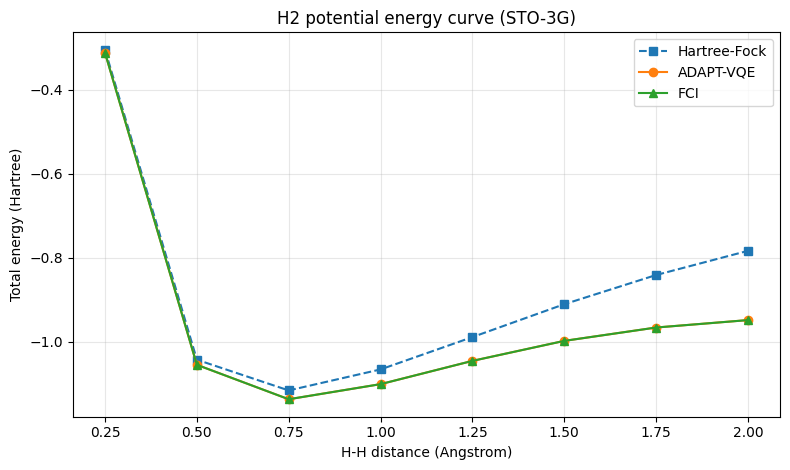

In [ ]:
print("R[Å]   HF[Ha]        ADAPT[Ha]     FCI[Ha]       |log10(err|[kcal/mol])  Nop  収束")
print("-" * 90)
for result in scan_results:
    print(
        f"{result['R']:4.2f}  {result['HF']: .9f}  {result['ADAPT']: .9f}  "
        f"{result['FCI']: .9f}      {result['error_kcal_mol']:9.5f}   "
        f"{result['n_operators']:2d}   {result['converged']}"
    )

for record, labels in zip(scan_results, selected_labels_by_distance):
    print(f"R={record['R']:.2f} Å: ", " -> ".join(labels) if labels else "演算子追加なし")

R_values = np.array([row["R"] for row in scan_results])
E_hf = np.array([row["HF"] for row in scan_results])
E_adapt = np.array([row["ADAPT"] for row in scan_results])
E_fci = np.array([row["FCI"] for row in scan_results])

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(R_values, E_hf, "s--", label="Hartree-Fock")
ax.plot(R_values, E_adapt, "o-", label="ADAPT-VQE")
ax.plot(R_values, E_fci, "^-", label="FCI")
ax.set_xlabel("H-H distance (Angstrom)")
ax.set_ylabel("Total energy (Hartree)")
ax.set_title("H2 potential energy curve (STO-3G)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## まとめ

ここでは、[Grimsley et al. (2019)](https://www.nature.com/articles/s41467-019-10988-2) で提案された手法を解説し、Qamomile で実装する手順をご紹介しました。
以下に、このページの重要情報をまとめます。

* ADAPT-VQE は、エネルギー勾配に基づいて演算子を選択し、アンザッツを逐次的に成長させる量子・古典ハイブリッドアルゴリズムです。
* 今回の実装では、演算子プールには、一般化された単一・二重フェルミオン励起演算子を利用しています。各候補の勾配は、ハミルトニアンとの交換子の期待値から評価することができます。
* Qamomile を用いることで、パラメトライズされた状態準備と期待値計算を、一つの量子カーネルとして記述できます。同じカーネルを、エネルギー評価と演算子選択の両方に利用可能です。
* ADAPT-VQE を用いて $\mathrm{H}_2$ のエネルギー曲線を計算したところ、FCI と一致する結果を得ることができました。
* 今回の結果は理想シミュレータによる小規模な検証です。より複雑な分子や実機での実行では、演算子プールの大きさ・勾配測定のコスト・回路 depth・ノイズの影響などを考慮する必要があるでしょう。